In [2]:
import pandas as pd
import matplotlib.pyplot as plt

transactions = pd.read_csv("../data/clean/transactions_clean.csv")

transactions["date"] = pd.to_datetime(transactions["date"])

In [4]:
print("Total transactions:", f"{len(transactions):,}")
print("Total transaction amount:", f"₹{transactions['amount'].sum():,.2f}")
print("Average transaction amount:", f"₹{transactions['amount'].mean():,.2f}")

display(transactions.head())

Total transactions: 500,000
Total transaction amount: ₹6,018,271,916.00
Average transaction amount: ₹12,036.54


,transaction_id,customer_id,account_id,date,transaction_type,amount,merchant,payment_mode,status
0,T000001,C06022,A12934,2026-02-11,Debit,4418,MakeMyTrip,UPI,Success
1,T000002,C08795,A14436,2026-04-21,Debit,4503,Netflix,Bank Transfer,Success
2,T000003,C03627,A17992,2026-01-10,Debit,3113,Uber,Credit Card,Success
3,T000004,C02899,A18286,2026-07-15,Credit,81075,Bank Refund,Credit Card,Failed
4,T000005,C05836,A11983,2026-01-31,Debit,3137,Amazon,UPI,Success


,transaction_count
payment_mode,
UPI,249859
Debit Card,100511
Credit Card,74963
Bank Transfer,49876
Net Banking,24791


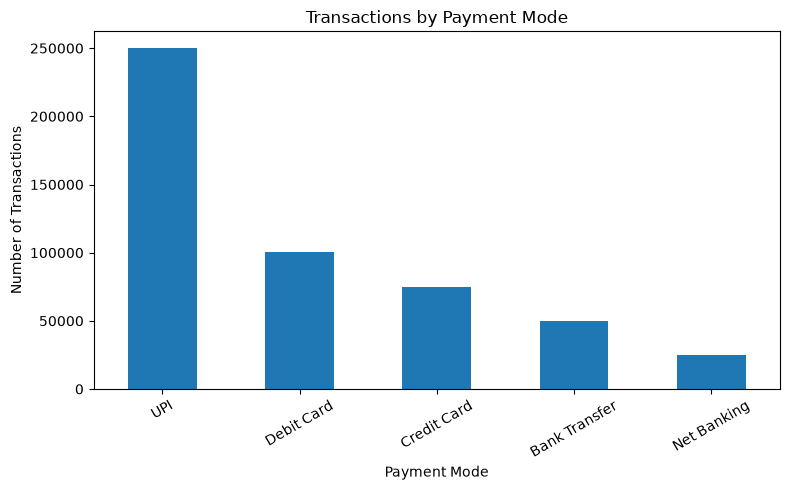

In [5]:
payment_summary = transactions["payment_mode"].value_counts().to_frame(
    "transaction_count"
)

display(payment_summary)

payment_summary.plot(kind="bar", figsize=(8, 5), legend=False)
plt.title("Transactions by Payment Mode")
plt.xlabel("Payment Mode")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Dominant Payment Channel: UPI is the overwhelmingly preferred payment mode (~250,000 transactions), accounting for half of all overall transaction volume.   

Card & Traditional Channels: Debit Card (~100,000) and Credit Card (~75,000) form a solid secondary layer, while Bank Transfer (~50,000) and Net Banking (~25,000) see lower usage.  

 Main Takeaway: Prioritize system stability and fast processing for UPI transactions, while optimizing checkout flows for card payments to boost conversion.  

,transaction_count,percentage
status,,
Success,460053,92.01
Failed,24930,4.99
Pending,15017,3.00


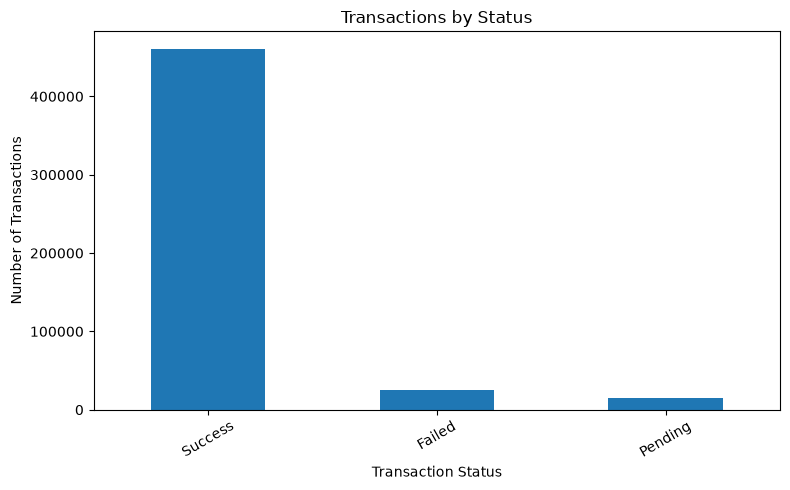

In [6]:
status_summary = transactions["status"].value_counts().to_frame(
    "transaction_count"
)

status_summary["percentage"] = (
    status_summary["transaction_count"] / len(transactions) * 100
).round(2)

display(status_summary)

status_summary["transaction_count"].plot(
    kind="bar", figsize=(8, 5), legend=False
)
plt.title("Transactions by Status")
plt.xlabel("Transaction Status")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

High Success Rate: The vast majority of transactions are Success (~460,000), indicating a reliable payment pipeline.

Minor Drop-offs: Failed (~25,000) and Pending (~15,000) transactions make up a small portion of the overall volume.

Main Takeaway: System reliability is strong; focus on reducing payment gateway failures to recover lost revenue from the ~25,000 failed attempts.

In [7]:
transaction_type_summary = transactions.groupby("transaction_type").agg(
    transaction_count=("transaction_id", "count"),
    total_amount=("amount", "sum"),
    average_amount=("amount", "mean")
).round(2)

display(
    transaction_type_summary.sort_values("total_amount", ascending=False)
)

,transaction_count,total_amount,average_amount
transaction_type,,,
Credit,99315,5014415638,50490.01
Debit,400685,1003856278,2505.35
